In [1]:
import pandas as pd

train = pd.read_csv('trainingData.csv')
print(train.shape)
train.head()

(19937, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


In [2]:
print(train['FLOOR'].value_counts())
print(train['BUILDINGID'].value_counts())

FLOOR
3    5048
1    5002
2    4416
0    4369
4    1102
Name: count, dtype: int64
BUILDINGID
2    9492
0    5249
1    5196
Name: count, dtype: int64


In [3]:
# 处理缺失值编码：100 → -105
X_train = train.iloc[:, :520].copy()
X_train = X_train.replace(100, -105)

y_train_floor = train['FLOOR']

# 确认处理成功
print(X_train.describe().iloc[:, :3])

             WAP001        WAP002   WAP003
count  19937.000000  19937.000000  19937.0
mean    -104.991273   -104.983699   -105.0
std        0.292228      0.531403      0.0
min     -105.000000   -105.000000   -105.0
25%     -105.000000   -105.000000   -105.0
50%     -105.000000   -105.000000   -105.0
75%     -105.000000   -105.000000   -105.0
max      -93.000000    -86.000000   -105.0


In [4]:
pd.crosstab(train['BUILDINGID'], train['FLOOR'])

FLOOR,0,1,2,3,4
BUILDINGID,,,,,
0,1059,1356,1443,1391,0
1,1368,1484,1396,948,0
2,1942,2162,1577,2709,1102


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train_floor, test_size=0.2, random_state=42
)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_tr, y_tr)

y_pred = clf.predict(X_val)
print("准确率:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

准确率: 0.9962387161484454
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       886
           1       1.00      1.00      1.00      1010
           2       1.00      1.00      1.00       882
           3       0.99      1.00      1.00       998
           4       1.00      1.00      1.00       212

    accuracy                           1.00      3988
   macro avg       1.00      1.00      1.00      3988
weighted avg       1.00      1.00      1.00      3988



In [6]:
val_data = pd.read_csv('validationData.csv')
X_test = val_data.iloc[:, :520].replace(100, -105)
y_test_floor = val_data['FLOOR']

y_test_pred = clf.predict(X_test)
print("官方验证集准确率:", accuracy_score(y_test_floor, y_test_pred))

官方验证集准确率: 0.9045904590459046


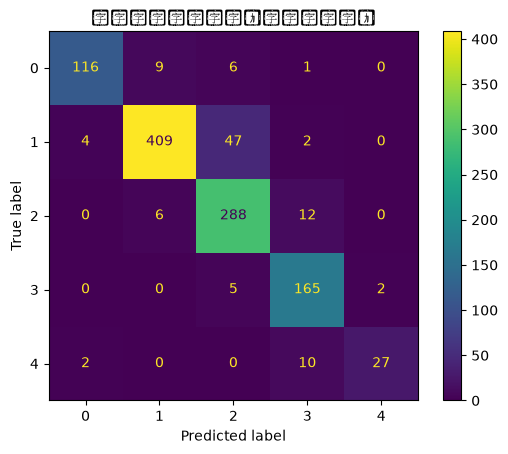

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test_floor, y_test_pred)
plt.title("楼层预测混淆矩阵（官方验证集）")
plt.show()

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_tr, y_tr)
y_pred_knn = knn.predict(X_val)
print("KNN准确率(本地验证集):", accuracy_score(y_val, y_pred_knn))

# 也在官方验证集上测一下，方便和随机森林对比
y_test_pred_knn = knn.predict(X_test)
print("KNN准确率(官方验证集):", accuracy_score(y_test_floor, y_test_pred_knn))

KNN准确率(本地验证集): 0.9954864593781344
KNN准确率(官方验证集): 0.9000900090009001


In [9]:
y_train_room = train['SPACEID']

X_tr_room, X_val_room, y_tr_room, y_val_room = train_test_split(
    X_train, y_train_room, test_size=0.2, random_state=42
)

clf_room = RandomForestClassifier(n_estimators=100, random_state=42)
clf_room.fit(X_tr_room, y_tr_room)

y_pred_room = clf_room.predict(X_val_room)
print("room(本地验证集):", accuracy_score(y_val_room, y_pred_room))

y_test_room = val_data['SPACEID']
y_test_pred_room = clf_room.predict(X_test)
print("room(官方验证集):", accuracy_score(y_test_room, y_test_pred_room))

room(本地验证集): 0.8600802407221665
room(官方验证集): 0.0


In [10]:
print("房间类别总数:", train['SPACEID'].nunique())

房间类别总数: 123


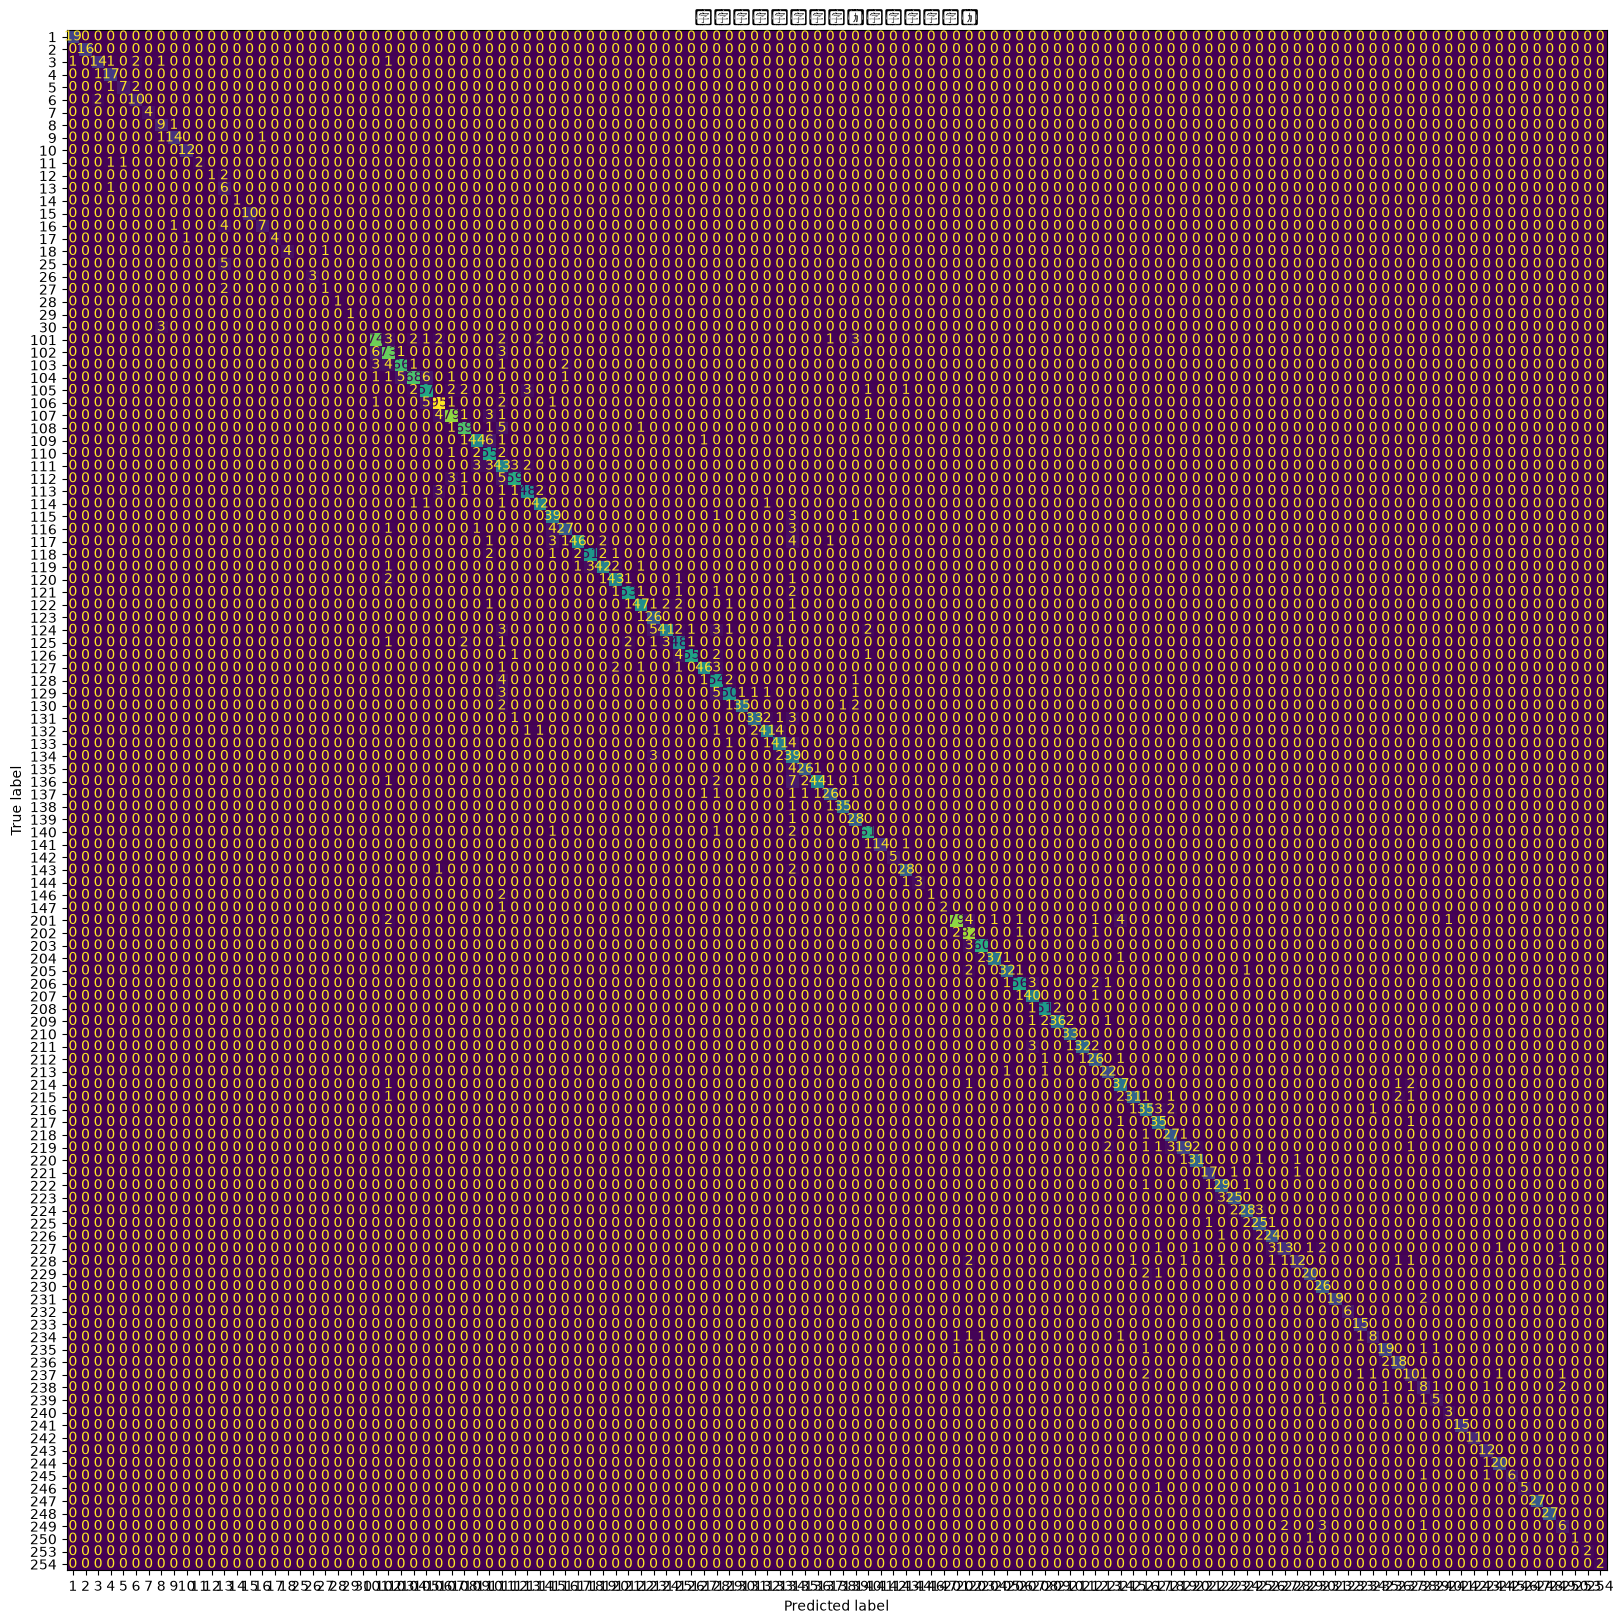

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 20))  # 放大图片尺寸，123个类别需要更大空间
ConfusionMatrixDisplay.from_predictions(y_val_room, y_pred_room, ax=ax, colorbar=False)
plt.title("房间预测混淆矩阵（本地验证集）")
plt.show()

In [12]:
import pandas as pd

# 找出预测错误的记录
errors = pd.DataFrame({'真实房间': y_val_room, '预测房间': y_pred_room})
errors_only = errors[errors['真实房间'] != errors['预测房间']]

# 统计哪些"真实房间→预测房间"的组合出现最多次
top_confusions = errors_only.groupby(['真实房间', '预测房间']).size().sort_values(ascending=False)
print(top_confusions.head(10))

真实房间  预测房间
136   134     7
104   105     6
102   101     6
109   110     6
25    13      5
108   111     5
112   111     5
104   103     5
106   105     5
129   128     5
dtype: int64


In [13]:
# 给房间预测加入楼层+建筑物作为额外特征
X_train_room_v2 = X_train.copy()
X_train_room_v2['FLOOR'] = train['FLOOR']
X_train_room_v2['BUILDINGID'] = train['BUILDINGID']

# 重新切分训练/本地验证集
X_tr_v2, X_val_v2, y_tr_v2, y_val_v2 = train_test_split(
    X_train_room_v2, y_train_room, test_size=0.2, random_state=42
)

# 训练新模型
clf_room_v2 = RandomForestClassifier(n_estimators=100, random_state=42)
clf_room_v2.fit(X_tr_v2, y_tr_v2)

y_pred_room_v2 = clf_room_v2.predict(X_val_v2)
print("加入楼层+建筑特征后，房间预测准确率:", accuracy_score(y_val_v2, y_pred_room_v2))
print("vs")
print("原始房间预测准确率(仅WiFi信号):", accuracy_score(y_val_room, y_pred_room))

加入楼层+建筑特征后，房间预测准确率: 0.8598294884653962
vs
原始房间预测准确率(仅WiFi信号): 0.8600802407221665


In [14]:
# 检查v2是否过拟合
y_train_pred_v2 = clf_room_v2.predict(X_tr_v2)
print("v2训练集准确率:", accuracy_score(y_tr_v2, y_train_pred_v2))
print("v2验证集准确率:", accuracy_score(y_val_v2, y_pred_room_v2))

v2训练集准确率: 0.9699667690764311
v2验证集准确率: 0.8598294884653962


In [15]:
clf_room_v4 = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,        # 限制树的深度
    min_samples_leaf=3,  # 避免树学得太细
    random_state=42
)
clf_room_v4.fit(X_tr_room, y_tr_room)

y_train_pred_v4 = clf_room_v4.predict(X_tr_room)
y_val_pred_v4 = clf_room_v4.predict(X_val_room)

print("v4训练集准确率:", accuracy_score(y_tr_room, y_train_pred_v4))
print("v4验证集准确率:", accuracy_score(y_val_room, y_val_pred_v4))

v4训练集准确率: 0.6786632390745502
v4验证集准确率: 0.5699598796389167


In [16]:
clf_room_v5 = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,         # 放宽深度限制
    min_samples_leaf=3,
    random_state=42
)
clf_room_v5.fit(X_tr_room, y_tr_room)

y_train_pred_v5 = clf_room_v5.predict(X_tr_room)
y_val_pred_v5 = clf_room_v5.predict(X_val_room)

print("v5训练集准确率:", accuracy_score(y_tr_room, y_train_pred_v5))
print("v5验证集准确率:", accuracy_score(y_val_room, y_val_pred_v5))

v5训练集准确率: 0.9028152235249859
v5验证集准确率: 0.7670511534603811


In [17]:
clf_room_v6 = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,   # 只限制这一个参数，不限制深度
    random_state=42
)
clf_room_v6.fit(X_tr_room, y_tr_room)

y_train_pred_v6 = clf_room_v6.predict(X_tr_room)
y_val_pred_v6 = clf_room_v6.predict(X_val_room)

print("v6训练集准确率:", accuracy_score(y_tr_room, y_train_pred_v6))
print("v6验证集准确率:", accuracy_score(y_val_room, y_val_pred_v6))

v6训练集准确率: 0.9549188036867515
v6验证集准确率: 0.8312437311935807


In [18]:
clf_room_v7 = RandomForestClassifier(
    n_estimators=300,   # 树的数量从100增加到300
    random_state=42
)
clf_room_v7.fit(X_tr_room, y_tr_room)

y_train_pred_v7 = clf_room_v7.predict(X_tr_room)
y_val_pred_v7 = clf_room_v7.predict(X_val_room)

print("v7训练集准确率:", accuracy_score(y_tr_room, y_train_pred_v7))
print("v7验证集准确率:", accuracy_score(y_val_room, y_val_pred_v7))

v7训练集准确率: 0.9693397705185278
v7验证集准确率: 0.8683550651955868


In [19]:
import pandas as pd

results = pd.DataFrame({'真实房间': y_val_room.values, '预测房间': y_val_pred_v7})

# 直接标记每一条预测是否正确
results['是否正确'] = results['真实房间'] == results['预测房间']

# 按真实房间分组，计算每组的正确率
room_accuracy = results.groupby('真实房间')['是否正确'].mean().sort_values()

print("预测准确率最低的10个房间:")
print(room_accuracy.head(10))

print("\n这些房间在验证集里各有多少条记录:")
print(results['真实房间'].value_counts()[room_accuracy.head(10).index])

预测准确率最低的10个房间:
真实房间
30     0.000000
25     0.000000
12     0.333333
27     0.333333
146    0.333333
11     0.500000
250    0.500000
249    0.500000
238    0.571429
16     0.583333
Name: 是否正确, dtype: float64

这些房间在验证集里各有多少条记录:
真实房间
30      3
25      5
12      3
27      3
146     3
11      4
250     2
249    12
238    14
16     12
Name: count, dtype: int64


In [20]:
from sklearn.neighbors import KNeighborsClassifier

# 用KNN预测房间（用最原始的X_tr_room/X_val_room，不加额外特征，方便跟随机森林基线对比）
knn_room = KNeighborsClassifier(n_neighbors=5)
knn_room.fit(X_tr_room, y_tr_room)

y_pred_room_knn = knn_room.predict(X_val_room)
print("KNN房间预测准确率(本地验证集):", accuracy_score(y_val_room, y_pred_room_knn))
print("---对比---")
print("随机森林房间预测准确率(基线):", accuracy_score(y_val_room, y_pred_room))
print("随机森林房间预测准确率(最优v7):", accuracy_score(y_val_room, y_val_pred_v7))

KNN房间预测准确率(本地验证集): 0.7680541624874624
---对比---
随机森林房间预测准确率(基线): 0.8600802407221665
随机森林房间预测准确率(最优v7): 0.8683550651955868


In [21]:
from sklearn.neural_network import MLPClassifier

# 神经网络对特征范围比较敏感，通常需要标准化，这一步先跳过看看效果，如果不理想再加
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp.fit(X_tr, y_tr)

y_pred_mlp = mlp.predict(X_test)
print("神经网络楼层预测准确率(官方验证集):", accuracy_score(y_test_floor, y_pred_mlp))
print("---对比---")
print("随机森林:", accuracy_score(y_test_floor, y_test_pred))
print("KNN:", accuracy_score(y_test_floor, knn.predict(X_test)))

神经网络楼层预测准确率(官方验证集): 0.8694869486948695
---对比---
随机森林: 0.9045904590459046
KNN: 0.9000900090009001


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_test_scaled = scaler.transform(X_test)

mlp_v2 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp_v2.fit(X_tr_scaled, y_tr)

y_pred_mlp_v2 = mlp_v2.predict(X_test_scaled)
print("标准化后神经网络准确率:", accuracy_score(y_test_floor, y_pred_mlp_v2))

标准化后神经网络准确率: 0.882988298829883


In [23]:
mlp_room = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp_room.fit(X_tr_room, y_tr_room)

y_pred_room_mlp = mlp_room.predict(X_val_room)
print("神经网络房间预测准确率(未标准化):", accuracy_score(y_val_room, y_pred_room_mlp))
print("---对比---")
print("随机森林(v7):", accuracy_score(y_val_room, y_val_pred_v7))
print("KNN:", accuracy_score(y_val_room, y_pred_room_knn))

神经网络房间预测准确率(未标准化): 0.02156469408224674
---对比---
随机森林(v7): 0.8683550651955868
KNN: 0.7680541624874624


In [24]:
X_tr_room_scaled = scaler.fit_transform(X_tr_room)
X_val_room_scaled = scaler.transform(X_val_room)

mlp_room_v2 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
mlp_room_v2.fit(X_tr_room_scaled, y_tr_room)

y_pred_room_mlp_v2 = mlp_room_v2.predict(X_val_room_scaled)
print("神经网络房间预测准确率(标准化后):", accuracy_score(y_val_room, y_pred_room_mlp_v2))

神经网络房间预测准确率(标准化后): 0.7419759277833501


In [25]:
print(train['LONGITUDE'].describe())
print(train['LATITUDE'].describe())

count    19937.000000
mean     -7464.275947
std        123.402010
min      -7691.338400
25%      -7594.737000
50%      -7423.060900
75%      -7359.193000
max      -7300.818990
Name: LONGITUDE, dtype: float64
count    1.993700e+04
mean     4.864871e+06
std      6.693318e+01
min      4.864746e+06
25%      4.864821e+06
50%      4.864852e+06
75%      4.864930e+06
max      4.865017e+06
Name: LATITUDE, dtype: float64


In [26]:
for precision in [0, 1, -1]:
    grouped = (train['LONGITUDE'].round(precision).astype(str) + '_' + 
               train['LATITUDE'].round(precision).astype(str))
    print(f"精度round({precision})：分出了 {grouped.nunique()} 个不同的组")

精度round(0)：分出了 502 个不同的组
精度round(1)：分出了 618 个不同的组
精度round(-1)：分出了 159 个不同的组


In [27]:
from sklearn.model_selection import GroupShuffleSplit

# 用round(0)精度构造位置分组标签
train['location_group'] = (train['LONGITUDE'].round(0).astype(str) + '_' + 
                            train['LATITUDE'].round(0).astype(str))

# 按分组切分，保证同一个位置的数据不会同时出现在训练集和验证集
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X_train, y_train_room, groups=train['location_group']))

X_tr_room_group = X_train.iloc[train_idx]
X_val_room_group = X_train.iloc[val_idx]
y_tr_room_group = y_train_room.iloc[train_idx]
y_val_room_group = y_train_room.iloc[val_idx]

print("训练集条数:", len(X_tr_room_group))
print("验证集条数:", len(X_val_room_group))

训练集条数: 16259
验证集条数: 3678


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

clf_room_group = RandomForestClassifier(n_estimators=300, random_state=42)
clf_room_group.fit(X_tr_room_group, y_tr_room_group)

y_pred_room_group = clf_room_group.predict(X_val_room_group)
print("按位置分组切分后的房间预测准确率:", accuracy_score(y_val_room_group, y_pred_room_group))
print("---对比---")
print("之前随机切分的房间预测准确率:", accuracy_score(y_val_room, y_val_pred_v7))

按位置分组切分后的房间预测准确率: 0.06253398586188146
---对比---
之前随机切分的房间预测准确率: 0.8683550651955868


In [29]:
train_rooms = set(y_tr_room_group.unique())
val_rooms = set(y_val_room_group.unique())
print("训练集里出现过的房间数:", len(train_rooms))
print("验证集里出现过的房间数:", len(val_rooms))
print("验证集里、但训练集完全没见过的房间数:", len(val_rooms - train_rooms))

训练集里出现过的房间数: 122
验证集里出现过的房间数: 84
验证集里、但训练集完全没见过的房间数: 1


In [30]:
# 看看同一个SPACEID，是否横跨了多个不同的建筑/楼层
room_building_check = train.groupby('SPACEID')[['BUILDINGID', 'FLOOR']].nunique()
print("有多少个SPACEID横跨了不止一个建筑:", (room_building_check['BUILDINGID'] > 1).sum())
print("有多少个SPACEID横跨了不止一个楼层:", (room_building_check['FLOOR'] > 1).sum())

有多少个SPACEID横跨了不止一个建筑: 86
有多少个SPACEID横跨了不止一个楼层: 105


In [31]:
# 构造真正唯一的房间标识：建筑+楼层+SPACEID组合
train['UNIQUE_ROOM'] = (train['BUILDINGID'].astype(str) + '_' + 
                         train['FLOOR'].astype(str) + '_' + 
                         train['SPACEID'].astype(str))
print("修正后，真正唯一的房间数量:", train['UNIQUE_ROOM'].nunique())

修正后，真正唯一的房间数量: 735


In [32]:
y_train_room_fixed = train['UNIQUE_ROOM']

X_tr_fixed, X_val_fixed, y_tr_fixed, y_val_fixed = train_test_split(
    X_train, y_train_room_fixed, test_size=0.2, random_state=42
)

clf_room_fixed = RandomForestClassifier(n_estimators=300, random_state=42)
clf_room_fixed.fit(X_tr_fixed, y_tr_fixed)

y_pred_room_fixed = clf_room_fixed.predict(X_val_fixed)
print("修正标签后，房间预测准确率(随机切分):", accuracy_score(y_val_fixed, y_pred_room_fixed))
print("---对比---")
print("之前用有歧义标签的准确率:", accuracy_score(y_val_room, y_val_pred_v7))

修正标签后，房间预测准确率(随机切分): 0.8688565697091274
---对比---
之前用有歧义标签的准确率: 0.8683550651955868


In [33]:
train['UNIQUE_ROOM'] = train['BUILDINGID'].astype(str) + '_' + train['FLOOR'].astype(str) + '_' + train['SPACEID'].astype(str)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx2, val_idx2 = next(gss2.split(X_train, train['UNIQUE_ROOM'], groups=train['location_group']))

X_tr_final = X_train.iloc[train_idx2]
X_val_final = X_train.iloc[val_idx2]
y_tr_final = train['UNIQUE_ROOM'].iloc[train_idx2]
y_val_final = train['UNIQUE_ROOM'].iloc[val_idx2]

clf_final = RandomForestClassifier(n_estimators=100, random_state=42)
clf_final.fit(X_tr_final, y_tr_final)
y_pred_final = clf_final.predict(X_val_final)
print("标签修正 + 位置分组切分后的准确率:", accuracy_score(y_val_final, y_pred_final))

标签修正 + 位置分组切分后的准确率: 0.055736813485589995
